In [13]:
from langgraph.graph import START,StateGraph,END
from typing import TypedDict,Annotated
from langchain_core.messages import BaseMessage, HumanMessage
from langchain_groq import ChatGroq
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import MemorySaver # new


In [3]:
class chatState(TypedDict):
    messages : Annotated[list[BaseMessage],add_messages]

In [4]:
llm = ChatGroq(model = "openai/gpt-oss-120b")

In [5]:
def chat_node(state: chatState):

    # take user query from state
    messages = state['messages']

    # send to llm
    response = llm.invoke(messages)

    # response store state
    return {'messages': [response]}

In [15]:
checkpointer = MemorySaver()#new
graph = StateGraph(chatState)

# add nodes
graph.add_node('chat_node', chat_node)

graph.add_edge(START, 'chat_node')
graph.add_edge('chat_node', END)

chatbot = graph.compile(checkpointer=checkpointer)#new

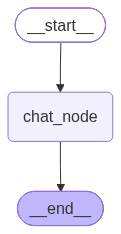

In [7]:
chatbot

In [10]:
initial_state = {
    'messages': [HumanMessage(content='What is the capital of spain')]
}

chatbot.invoke(initial_state)['messages'][-1].content

'The capital of Spain is **Madrid**.'

In [20]:
thread_id = '1'
while True:
    user_mssg = input('Type here: ')
    print('User:', user_mssg)

    if user_mssg.strip().lower() in ['exit','quit','bye']:
        break
    
    config ={'configurable':{'thread_id':thread_id}}
    response = chatbot.invoke({'messages':[HumanMessage(content=user_mssg)]}, config=config)
    print('ai',response['messages'][-1].content)

User: hi my name is v
ai Hello, V! Nice to meet you. How can I help you today?
User: whts my name?
ai Your name is V.
User: exit


isme use yaad nhi rh rha kyoki haar baar state end ho rhi h and agle ques ke liye fir se strt ho rhi h

isliye hum persistenace ka concept use krenge jisme 

end hone pr hum state ki chijo ko erase nhi krenge khi store kr lenge and usko append kr denge firse jb initialize hogi state jisse chatbot ko purana bhi yaad rhega

two options to store => 1. db me jisse kbhi bhi access kr skte h 
2. RAM me

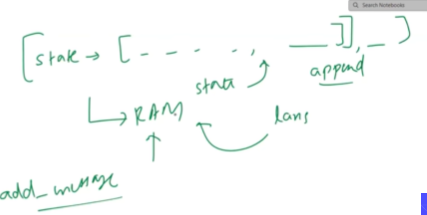